# Curva DI: inclinada × invertida

**O que uma curva invertida sinaliza — reprodução completa das contas e dos gráficos do vídeo**

Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires) · 09/2026

---

Este notebook reproduz, passo a passo, todos os números e gráficos do Reel *"Curva DI: inclinada × invertida"*. A ideia é que você consiga refazer cada conta sozinho e trocar o arquivo por uma data mais recente.

**Dados:** `contratos_di_futuro.csv`, com as taxas dos contratos futuros de DI de 1 dia (DI1) negociados na B3, último negócio de **27/08/2026**.

## 1. Bibliotecas e parâmetros

Usamos quatro bibliotecas:

- **pandas / numpy**: leitura e contas.
- **matplotlib**: gráficos.
- **bizdays**: contagem de dias úteis com o calendário **ANBIMA**, que é o calendário oficial para o DI1.

Se não tiver o `bizdays`, instale com `pip install bizdays`. O pacote já traz o calendário ANBIMA embutido, sem precisar baixar feriados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bizdays import Calendar

# ---- parâmetros ----
ARQUIVO = "contratos_di_futuro.csv"     # na mesma pasta do notebook

DATA_REF = pd.Timestamp("2026-08-27")   # data do último negócio no arquivo
VOLUME_MIN = 1e9                         # R$ 1 bilhão: corte de liquidez

cal = Calendar.load("ANBIMA")

# ---- estilo dos gráficos (mesma paleta do vídeo) ----
BG, WHITE, GREY, CYAN, AMBER, PINK = "#07080D", "#E6E6E9", "#6C6D72", "#4AADD6", "#E8A13A", "#DE235B"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GREY, "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "text.color": WHITE, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "DejaVu Sans Mono", "figure.figsize": (9, 5), "figure.dpi": 110,
})

## 2. Leitura e limpeza do arquivo

O CSV tem seis colunas:

| Coluna | Significado | Usada? |
|---|---|---|
| `Código` | Ticker do contrato, ex.: `DI1F27` | sim |
| `Vencimento` | Data de vencimento (dd/mm/aaaa) | sim |
| `Taxa de juros` | Taxa do último negócio, **% a.a., base 252** | sim |
| `Variação` | Variação percentual da taxa no dia | não |
| `Data/Hora do Últ. negócio` | Carimbo do último negócio | não |
| `Volume negociado` | Volume financeiro em R$ | sim (filtro) |

**Cuidado com o formato brasileiro.** O volume vem como `"3.233.585.904,66"`, com ponto separando milhar e vírgula separando decimal. Para converter em número, primeiro removemos os pontos e depois trocamos a vírgula por ponto.

**Como ler o código.** Em `DI1F27`, `DI1` é o ativo, `F` é o mês de vencimento e `27` é o ano. A B3 usa estas letras para os meses:

| F | G | H | J | K | M | N | Q | U | V | X | Z |
|---|---|---|---|---|---|---|---|---|---|---|---|
| jan | fev | mar | abr | mai | jun | jul | ago | set | out | nov | dez |

In [2]:
di = pd.read_csv(ARQUIVO)
di.columns = ["codigo", "vencimento", "taxa", "variacao", "ultimo_negocio", "volume"]

di["vencimento"] = pd.to_datetime(di["vencimento"], dayfirst=True)
di["volume"] = (di["volume"].str.replace(".", "", regex=False)
                            .str.replace(",", ".", regex=False)
                            .astype(float))
di["taxa"] = di["taxa"].astype(float)

print(f"{len(di)} contratos | vencimentos de {di.vencimento.min():%d/%m/%Y} a {di.vencimento.max():%d/%m/%Y}")
di.head(8)

43 contratos | vencimentos de 01/09/2026 a 01/01/2039


,codigo,vencimento,taxa,variacao,ultimo_negocio,volume
0,DI1U26,2026-09-01,13.899,-0.01%,27/08/2026 04:25,3.233586e+09
1,DI1V26,2026-10-01,13.805,-0.09%,27/08/2026 05:14,5.094367e+10
2,DI1X26,2026-11-01,13.741,-0.07%,27/08/2026 05:03,1.321164e+10
3,DI1Z26,2026-12-01,13.680,-0.11%,27/08/2026 04:48,1.081237e+10
4,DI1F27,2027-01-01,13.635,-0.26%,27/08/2026 05:15,7.198722e+10
5,DI1G27,2027-02-01,13.635,-0.11%,27/08/2026 04:23,4.106335e+08
6,DI1H27,2027-03-01,13.625,-0.33%,27/08/2026 05:10,7.197789e+08
7,DI1J27,2027-04-01,13.635,-0.40%,27/08/2026 05:17,1.255101e+10


## 3. Dias úteis (du) — a unidade de tempo do DI

No mercado brasileiro, a taxa do DI1 é **exponencial, anualizada na base de 252 dias úteis**. O preço unitário (PU) de um contrato é

$$
PU = \frac{100\,000}{(1 + \text{taxa})^{du/252}}
$$

em que $du$ é o número de **dias úteis** entre a data de referência e o vencimento.

Dois detalhes importam aqui:

1. **O vencimento é o primeiro dia útil do mês.** A data do arquivo é sempre dia 01. Se o dia 01 não for útil (por exemplo, 01/01 é feriado), o vencimento vai para o próximo dia útil. É isso que `cal.adjust_next` faz.
2. **Contagem.** `cal.bizdays(inicio, fim)` conta os dias úteis entre as duas datas, com um dos extremos incluído e o outro não. É a mesma contagem de dias úteis usada no DI. Exemplo: de 27/08/2026 até 01/09/2026 são 3 du.

Com isso, o prazo em anos fica $\tau = du/252$.

In [3]:
di["venc_util"] = [cal.adjust_next(v.date()) for v in di["vencimento"]]
di["du"] = [cal.bizdays(DATA_REF.date(), v) for v in di["venc_util"]]
di["anos"] = di["du"] / 252
di["pu"] = 100_000 / (1 + di["taxa"] / 100) ** (di["du"] / 252)

di[["codigo", "vencimento", "venc_util", "du", "anos", "taxa", "pu"]].head(8)

,codigo,vencimento,venc_util,du,anos,taxa,pu
0,DI1U26,2026-09-01,2026-09-01,3,0.011905,13.899,99845.189117
1,DI1V26,2026-10-01,2026-10-01,24,0.095238,13.805,98775.969413
2,DI1X26,2026-11-01,2026-11-03,45,0.178571,13.741,97727.055533
3,DI1Z26,2026-12-01,2026-12-01,64,0.253968,13.680,96796.134704
4,DI1F27,2027-01-01,2027-01-04,86,0.341270,13.635,95731.615734
5,DI1G27,2027-02-01,2027-02-01,106,0.420635,13.635,94765.370606
6,DI1H27,2027-03-01,2027-03-01,124,0.492063,13.625,93908.157766
7,DI1J27,2027-04-01,2027-04-01,146,0.579365,13.635,92862.039636


## 4. Filtro de liquidez

Nem todo vencimento negocia bem. Contratos com volume muito baixo têm taxas pouco confiáveis: às vezes o "último negócio" foi um lote pequeno fora do preço justo. Um exemplo é o `DI1F39`, que negociou menos de R$ 40 mil.

No vídeo, ficaram só os vencimentos com **volume ≥ R$ 1 bi**. O corte é uma escolha prática, não uma regra de mercado. Teste outros valores e veja como a curva muda.

In [4]:
liq = di[di["volume"] >= VOLUME_MIN].reset_index(drop=True)
fora = di[di["volume"] < VOLUME_MIN]

print(f"Mantidos: {len(liq)} | Removidos: {len(fora)}")
print("Removidos:", ", ".join(fora["codigo"]))
liq[["codigo", "du", "anos", "taxa", "volume"]].assign(volume_bi=lambda x: (x.volume/1e9).round(2)).drop(columns="volume")

Mantidos: 19 | Removidos: 24
Removidos: DI1G27, DI1H27, DI1K27, DI1M27, DI1Q27, DI1X27, DI1Z27, DI1J28, DI1X28, DI1Z28, DI1J29, DI1V29, DI1X29, DI1Z29, DI1J30, DI1N30, DI1V30, DI1J31, DI1N31, DI1V31, DI1F34, DI1F36, DI1F38, DI1F39


,codigo,du,anos,taxa,volume_bi
0,DI1U26,3,0.011905,13.899,3.23
1,DI1V26,24,0.095238,13.805,50.94
2,DI1X26,45,0.178571,13.741,13.21
3,DI1Z26,64,0.253968,13.680,10.81
4,DI1F27,86,0.341270,13.635,71.99
5,DI1J27,146,0.579365,13.635,12.55
6,DI1N27,209,0.829365,13.685,15.73
7,DI1V27,274,1.087302,13.735,2.29
8,DI1F28,337,1.337302,13.765,55.68
9,DI1N28,461,1.829365,13.915,3.43


## 5. Curva normal × invertida

Antes dos dados reais, o vídeo mostra dois formatos típicos de curva. As curvas desta seção **não são dados de mercado**. Elas saem de uma forma funcional simples:

$$
r(\tau) = r_0 + s\,\left(1 - e^{-\tau/2{,}2}\right)
$$

- $r_0 = 12\%$ é o "juro de hoje", o ponto de partida.
- $s$ é o quanto a curva sobe ($s>0$, **inclinada**) ou desce ($s<0$, **invertida**) ao longo dos prazos.
- O termo exponencial faz a curva andar rápido nos primeiros anos e estabilizar depois, parecido com uma curva real.

**Curva inclinada (normal).** Prazos mais longos pagam mais. A explicação clássica é o **prêmio de prazo**: quem empresta por mais tempo carrega mais risco (inflação, fiscal, marcação a mercado) e cobra por isso.

**Curva invertida.** O curto paga mais que o longo. Na leitura mais comum, o mercado espera que o juro de curto prazo **caia** no futuro.

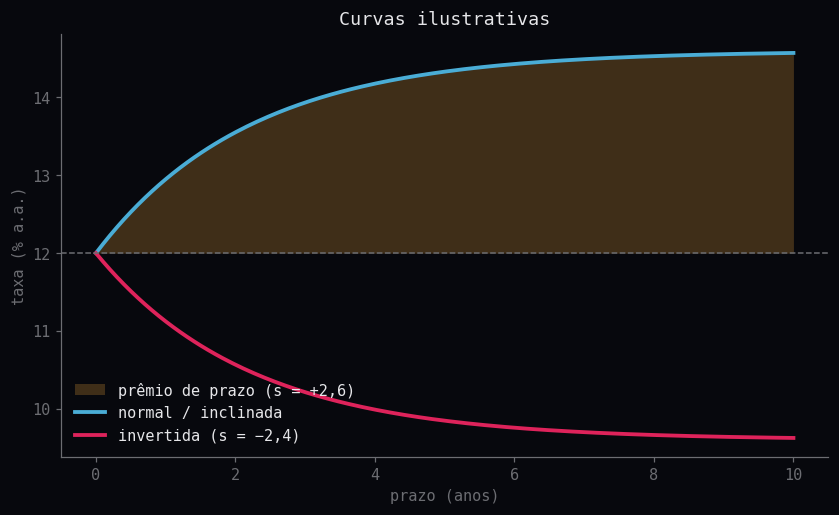

In [5]:
tau = np.linspace(0, 10, 200)
r0 = 12.0
curva = lambda s: r0 + s * (1 - np.exp(-tau / 2.2))

fig, ax = plt.subplots()
ax.fill_between(tau, curva(2.6), r0, color=AMBER, alpha=0.25, lw=0, label="prêmio de prazo (s = +2,6)")
ax.plot(tau, curva(2.6), color=CYAN, lw=2.5, label="normal / inclinada")
ax.plot(tau, curva(-2.4), color=PINK, lw=2.5, label="invertida (s = −2,4)")
ax.axhline(r0, ls="--", color=GREY, lw=1)
ax.set(xlabel="prazo (anos)", ylabel="taxa (% a.a.)", title="Curvas ilustrativas")
ax.legend(frameon=False)
plt.show()

## 6. Por que "curto > longo" significa cortes: a taxa a termo

Pense em duas formas de aplicar dinheiro de hoje até o prazo $du_2$:

- **(A)** aplicar direto até $du_2$ pela taxa longa $r_2$;
- **(B)** aplicar até $du_1$ pela taxa curta $r_1$ e, de $du_1$ até $du_2$, reaplicar por uma taxa $f$ travada hoje.

Sem arbitragem, as duas precisam render o mesmo:

$$
(1+r_2)^{du_2/252} = (1+r_1)^{du_1/252}\;(1+f)^{(du_2-du_1)/252}
$$

Isolando $f$, a **taxa a termo** (forward) entre $du_1$ e $du_2$:

$$
\boxed{\,f = \left[\frac{(1+r_2)^{du_2/252}}{(1+r_1)^{du_1/252}}\right]^{252/(du_2-du_1)} - 1\,}
$$

**A intuição.** A taxa longa é uma "média" composta da taxa curta com a taxa a termo. Se $r_2 < r_1$, a única forma de a média ficar abaixo de $r_1$ é $f$ também estar abaixo. Logo, **curva invertida ⇔ taxa a termo abaixo da taxa curta.**

**A ressalva.** Pela *hipótese das expectativas*, $f$ seria a expectativa do CDI futuro. Na prática, $f$ = expectativa + **prêmio de prazo**. Então uma taxa a termo alta pode ser prêmio, e não só expectativa de alta. Voltamos a isso na seção 11.

In [6]:
def taxa_termo(r1, du1, r2, du2):
    '''Taxa a termo (% a.a., base 252) entre du1 e du2. r1, r2 em % a.a.'''
    fator1 = (1 + r1 / 100) ** (du1 / 252)
    fator2 = (1 + r2 / 100) ** (du2 / 252)
    return ((fator2 / fator1) ** (252 / (du2 - du1)) - 1) * 100

# checagem: exemplo simples com 1 e 2 anos
r1, r2 = 14.0, 13.0
f = taxa_termo(r1, 252, r2, 504)
print(f"r1 = {r1}% (1 ano), r2 = {r2}% (2 anos)  →  termo 1a→2a = {f:.3f}%")
print(f"verificação: (1,14)·(1+f) = {1.14*(1+f/100):.6f}  vs  (1,13)² = {1.13**2:.6f}")

r1 = 14.0% (1 ano), r2 = 13.0% (2 anos)  →  termo 1a→2a = 12.009%
verificação: (1,14)·(1+f) = 1.276900  vs  (1,13)² = 1.276900


## 7. A curva DI real em 27/08/2026

Agora os dados. No gráfico:

- o eixo x é o prazo em anos ($du/252$);
- cada ponto é um vencimento líquido;
- o **tamanho do ponto** é proporcional ao $\log_{10}$ do volume, para destacar os vértices mais negociados (F27, F28, F29, F31…).

O formato que aparece não é "invertido" nem "normal" puro. É uma **colher**: a curva cai nos primeiros meses, faz um mínimo e depois sobe.

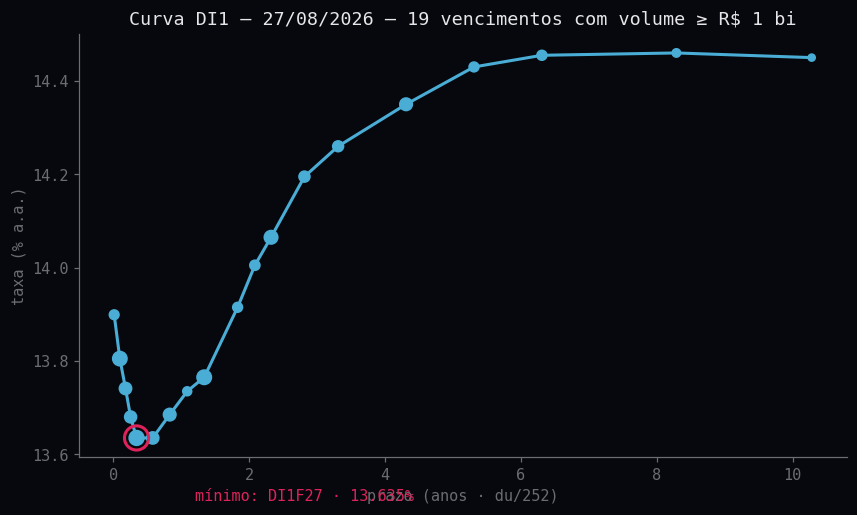

Vértice mais curto: DI1U26 = 13.899%  (3 du)
Mínimo da curva:    DI1F27 = 13.635%
Vértice mais longo: DI1F37 = 14.450%


In [ ]:
i_min = liq["taxa"].idxmin()
vmin = liq.loc[i_min]
tamanho = 20 + 40 * (np.log10(liq["volume"]) - 9)

fig, ax = plt.subplots()
ax.plot(liq["anos"], liq["taxa"], color=CYAN, lw=2)
ax.scatter(liq["anos"], liq["taxa"], s=tamanho, color=CYAN, zorder=3)
ax.scatter([vmin.anos], [vmin.taxa], s=250, facecolors="none", edgecolors=PINK, lw=2, zorder=4)
ax.annotate(f"mínimo: {vmin.codigo} · {vmin.taxa:.3f}%", (vmin.anos, vmin.taxa),
            xytext=(1.2, 13.5), color=PINK)
ax.set(xlabel="prazo (anos · du/252)", ylabel="taxa (% a.a.)",
       title=f"Curva DI1 — {DATA_REF:%d/%m/%Y} — {len(liq)} vencimentos com volume ≥ R$ 1 bi")
plt.show()

print(f"Vértice mais curto: {liq.iloc[0].codigo} = {liq.iloc[0].taxa:.3f}%  ({liq.iloc[0].du} du)")
print(f"Mínimo da curva:    {vmin.codigo} = {vmin.taxa:.3f}%")
print(f"Vértice mais longo: {liq.iloc[-1].codigo} = {liq.iloc[-1].taxa:.3f}%")

## 8. Zoom no curto: onde está a inversão

Olhando só o primeiro ano e meio, a curva parte do `DI1U26`, que vence em 3 dias úteis. Esse contrato funciona como uma boa aproximação do **CDI atual**. A partir dele, a curva desce até o `DI1F27`.

A **inclinação do trecho curto** é medida em pontos-base (1 bp = 0,01 p.p.):

$$
\text{inclinação}_{\,U26 \to F27} = (r_{F27} - r_{U26}) \times 100 \text{ bp}
$$

Negativa = trecho invertido.

> **Nota:** o `DI1J27` tem exatamente a mesma taxa do F27 (13,635%). O `idxmin` do pandas devolve a primeira ocorrência, por isso o mínimo aparece como F27.

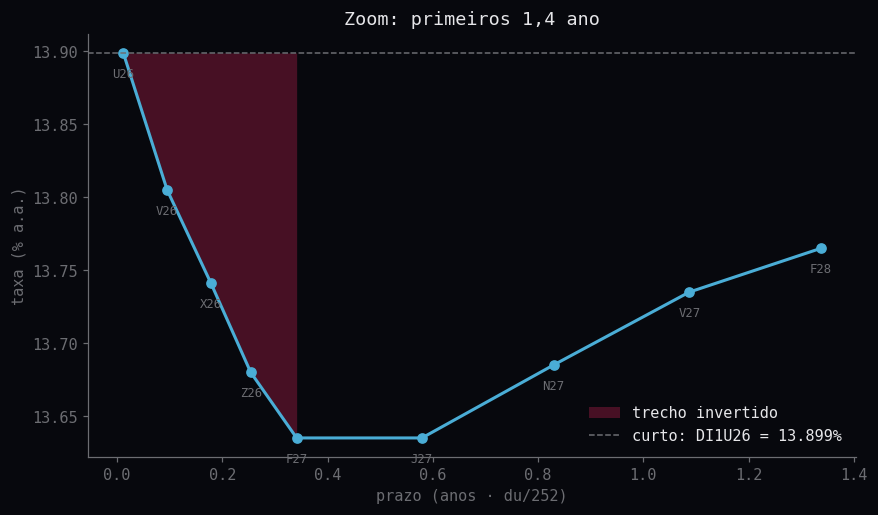

F27 − U26 = -26.4 bp


In [8]:
curto = liq[liq["anos"] <= 1.4].reset_index(drop=True)
u26 = liq.loc[liq.codigo == "DI1U26"].iloc[0]
f27 = liq.loc[liq.codigo == "DI1F27"].iloc[0]
spread_curto = (f27.taxa - u26.taxa) * 100

fig, ax = plt.subplots()
ate_min = curto.loc[:curto.taxa.idxmin()]
ax.fill_between(ate_min.anos, ate_min.taxa, u26.taxa, color=PINK, alpha=0.3, lw=0, label="trecho invertido")
ax.plot(curto.anos, curto.taxa, "o-", color=CYAN, lw=2)
ax.axhline(u26.taxa, ls="--", color=GREY, lw=1, label=f"curto: DI1U26 = {u26.taxa:.3f}%")
for _, r in curto.iterrows():
    ax.annotate(r.codigo[3:], (r.anos, r.taxa), xytext=(0, -16), textcoords="offset points",
                ha="center", color=GREY, fontsize=8)
ax.set(xlabel="prazo (anos · du/252)", ylabel="taxa (% a.a.)", title="Zoom: primeiros 1,4 ano")
ax.legend(frameon=False)
plt.show()

print(f"F27 − U26 = {spread_curto:.1f} bp")

## 9. Taxas a termo implícitas

Aplicamos a fórmula da seção 6 a pares de vencimentos líquidos.

**Primeiro, todos os pares consecutivos.** É a visão mais fina da curva, mas também a mais ruidosa: pequenos erros de preço entre vértices próximos viram oscilações grandes na taxa a termo.

**Depois, os seis trechos do vídeo,** usando os vértices de janeiro, que são os mais líquidos, para ter uma leitura mais limpa:

`U26→F27`, `F27→F28`, `F28→F29`, `F29→F31`, `F31→F33`, `F33→F37`

**Como ler o gráfico.** Barras **abaixo da linha tracejada** (a taxa curta de hoje) indicam que o mercado precifica um CDI médio menor que o atual naquele trecho. Barras acima indicam taxa maior, por expectativa de alta, por prêmio de prazo ou pelos dois.

In [9]:
# (a) pares consecutivos
consec = pd.DataFrame({
    "de": liq.codigo[:-1].values, "ate": liq.codigo[1:].values,
    "du1": liq.du[:-1].values, "du2": liq.du[1:].values,
    "termo_%": [taxa_termo(liq.taxa[i], liq.du[i], liq.taxa[i+1], liq.du[i+1]) for i in range(len(liq)-1)],
})
consec.round(3)

,de,ate,du1,du2,termo_%
0,DI1U26,DI1V26,3,24,13.792
1,DI1V26,DI1X26,24,45,13.668
2,DI1X26,DI1Z26,45,64,13.536
3,DI1Z26,DI1F27,64,86,13.504
4,DI1F27,DI1J27,86,146,13.635
5,DI1J27,DI1N27,146,209,13.801
6,DI1N27,DI1V27,209,274,13.896
7,DI1V27,DI1F28,274,337,13.896
8,DI1F28,DI1N28,337,461,14.324
9,DI1N28,DI1V28,461,525,14.655


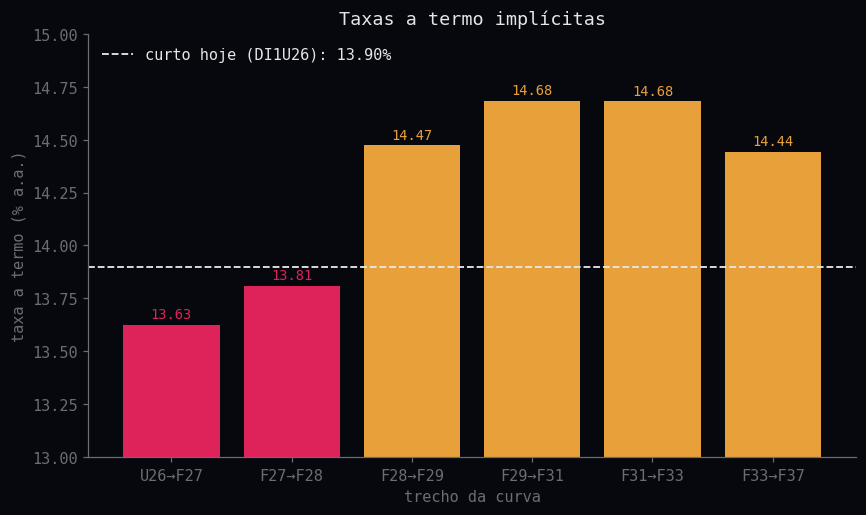

,trecho,termo_%
0,U26→F27,13.625
1,F27→F28,13.810
2,F28→F29,14.474
3,F29→F31,14.684
4,F31→F33,14.682
5,F33→F37,14.442


In [10]:
# (b) trechos do vídeo
pares = [("DI1U26","DI1F27"), ("DI1F27","DI1F28"), ("DI1F28","DI1F29"),
         ("DI1F29","DI1F31"), ("DI1F31","DI1F33"), ("DI1F33","DI1F37")]
L = liq.set_index("codigo")
termos = pd.DataFrame([{
    "trecho": f"{a[3:]}→{b[3:]}",
    "termo_%": taxa_termo(L.loc[a,"taxa"], L.loc[a,"du"], L.loc[b,"taxa"], L.loc[b,"du"]),
} for a, b in pares])

cores = [PINK if v < u26.taxa else AMBER for v in termos["termo_%"]]
fig, ax = plt.subplots()
ax.bar(termos["trecho"], termos["termo_%"], color=cores)
ax.axhline(u26.taxa, ls="--", color=WHITE, lw=1.2, label=f"curto hoje (DI1U26): {u26.taxa:.2f}%")
for i, v in enumerate(termos["termo_%"]):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", color=cores[i], fontsize=9)
ax.set_ylim(13.0, 15.0)
ax.set(xlabel="trecho da curva", ylabel="taxa a termo (% a.a.)", title="Taxas a termo implícitas")
ax.legend(frameon=False, loc="upper left")
plt.show()
termos.round(3)

### Checagem de consistência

Se as taxas a termo estão certas, **compor** a taxa curta com todos os termos em sequência precisa devolver exatamente a taxa do vértice final. Em outras palavras, a curva é recuperada a partir dos seus próprios termos.

In [11]:
fator = (1 + L.loc["DI1U26","taxa"]/100) ** (L.loc["DI1U26","du"]/252)
for (a, b), f in zip(pares, termos["termo_%"]):
    fator *= (1 + f/100) ** ((L.loc[b,"du"] - L.loc[a,"du"]) / 252)
r_recuperada = (fator ** (252 / L.loc["DI1F37","du"]) - 1) * 100
print(f"DI1F37 no arquivo: {L.loc['DI1F37','taxa']:.6f}%  |  recomposto pelos termos: {r_recuperada:.6f}%")

DI1F37 no arquivo: 14.450000%  |  recomposto pelos termos: 14.450000%


## 10. Medidas de inclinação

As medidas mais simples de inclinação são diferenças entre taxas de dois vértices, em bp. O vídeo usa três:

| Medida | Leitura |
|---|---|
| **F27 − U26** | Trecho curtíssimo: sinaliza cortes (ou altas) nos próximos meses |
| **F29 − F27** | Inclinação curta/intermediária (≈ 2 anos) |
| **F33 − F27** | Inclinação longa (≈ 6 anos): costuma carregar mais prêmio de prazo |

Não existe uma medida "oficial". Mesas e relatórios usam pares diferentes, por exemplo F27×F33 ou F28×F31. O importante é manter o mesmo par ao comparar datas.

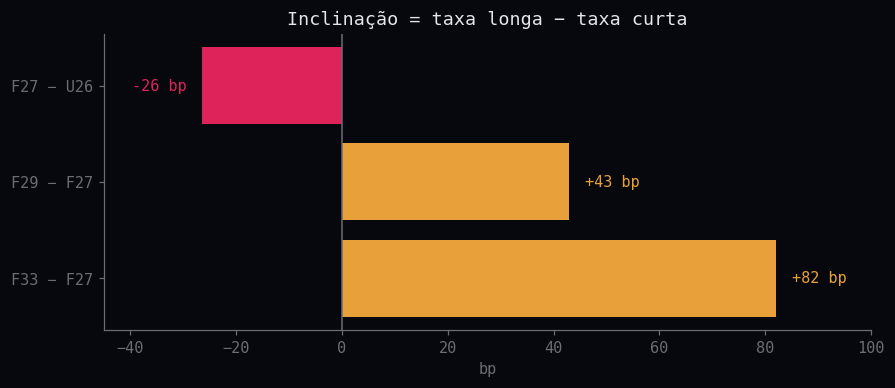

,medida,bp
0,F27 − U26,-26.4
1,F29 − F27,43.0
2,F33 − F27,82.0


In [12]:
incl = pd.DataFrame({
    "medida": ["F27 − U26", "F29 − F27", "F33 − F27"],
    "bp": [(L.loc["DI1F27","taxa"] - L.loc["DI1U26","taxa"]) * 100,
           (L.loc["DI1F29","taxa"] - L.loc["DI1F27","taxa"]) * 100,
           (L.loc["DI1F33","taxa"] - L.loc["DI1F27","taxa"]) * 100],
})
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(incl["medida"], incl["bp"], color=[PINK if v < 0 else AMBER for v in incl["bp"]])
ax.axvline(0, color=GREY, lw=1)
for i, v in enumerate(incl["bp"]):
    ax.text(v + (3 if v > 0 else -3), i, f"{v:+.0f} bp", va="center",
            ha="left" if v > 0 else "right", color=PINK if v < 0 else AMBER)
ax.invert_yaxis(); ax.set_xlim(-45, 100)
ax.set(xlabel="bp", title="Inclinação = taxa longa − taxa curta")
plt.show()
incl.round(1)

## 11. Interpretação e limitações

**O que os dados de 27/08/2026 dizem**

- **Trecho curto invertido, mas pouco:** −26 bp entre U26 e F27. As taxas a termo até o início de 2028 ficam abaixo do CDI implícito no U26, o que é consistente com o mercado precificando **algum alívio** no juro curto.
- **Do segundo ano em diante, curva inclinada:** os termos sobem para a faixa de 14,4%–14,7%, acima da taxa curta.

**Por que "inversão sinaliza cortes, não é promessa"**

1. **Prêmio de prazo.** A taxa a termo não é só expectativa. Parte dela é compensação por risco, e esse prêmio varia no tempo. Um termo alto no longo pode ser prêmio, não expectativa de alta do CDI.
2. **Expectativas mudam.** A curva é uma fotografia de um dia. Ela reprecifica a cada dado de inflação, comunicação do Copom ou choque fiscal.
3. **Um único dia, último negócio.** Usamos o último negócio de cada contrato, que pode ter ocorrido em horários diferentes, e não o ajuste oficial. Para pesquisa, prefira as taxas de ajuste da B3 ou a curva de referência da ANBIMA.
4. **Filtro de liquidez arbitrário.** Com R$ 1 bi o resultado fica mais limpo, mas outros cortes mudam os termos entre vértices próximos.
5. **Termos entre vértices próximos são ruidosos.** Veja a tabela de pares consecutivos: diferenças de 1–2 bp na taxa viram dezenas de bp no termo.

**Próximos passos sugeridos**

- Repetir com datas diferentes e montar uma série histórica da inclinação (F27−U26, F33−F27).
- Comparar a taxa a termo do trecho curto com as projeções de Selic do Boletim Focus. A diferença entre as duas dá uma medida rudimentar de prêmio.
- Interpolar a curva (flat-forward, que é o padrão do mercado brasileiro) para ter vértices fixos, como 1, 2 e 5 anos.

---
Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires)

© 2026 · Conteúdo educacional. Não é recomendação de investimento.